#### Defining the physical setup the code is emulating

A camera is positioned so that it can capture the motion of a wave (soltion) in a wave-flume. 
The camera has a limited field of view: L, and a fixed number of pixels in the frame: N. 

For periodic waves we require that a whole number of waves can pass in L, this is so that the FFT makes sense, a period is captured. 
Looking at solitons this can be done with zero-padding, forcing the wave to get the dimensions needed for periodization. 

In [2]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *

import numpy as np
import matplotlib.pyplot as plt

In [3]:
c1  = Camera(L = 4*np.pi , N=2**7, dt=1e-3)

In [4]:
w1 = KdVNewton(P=c1.L, target_amp=1,mean=0, camera=c1)
w1.solve_w_continuation()
w2 = KdVNewton(P=c1.L/2, target_amp=1,mean=0, camera=c1)
w2.solve_w_continuation()


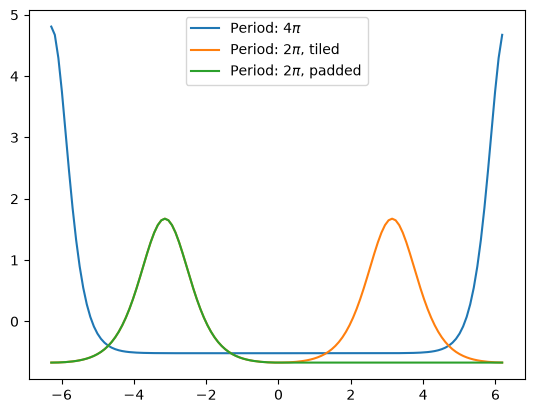

In [5]:
plt.plot(c1.x, w1.get_physical(w1.phi_hat), label = r"Period: $4\pi$");

phi2 = w2.get_physical(w2.phi_hat)
phi2 = np.roll(phi2, int(w2.N//2))
#And for the wave of half period one can tile it, (copy)
tiled = np.tile(phi2, int(c1.L//w2.P))
plt.plot(c1.x, tiled, label = r"Period: $2\pi$, tiled");
#Or one can zero-pad it
padded = np.zeros(c1.N) - np.abs(np.min(phi2))
padded[:w2.N] = phi2
plt.plot(c1.x, padded, label = r"Period: $2\pi$, padded");
plt.legend()
plt.show()



In [6]:
#Tiling and padding are however not equivalent, let us solve them in time:
T=5
sTile = KdV(camera=c1, T=T, u0=tiled)
t,tiled_sol = sTile.splitStep()

animate_solution_nb(c1.x,tiled_sol)

In [7]:
sTile.conservation()
# A = tiled_sol.max(axis=1) - tiled_sol.min(axis = 1)
# plt.plot(A)

----- Conservation of  Mass -----
Initial Mass: 1.42e-16
Final Mass: 2.40e-16
Maximum error: 5.56e-16
Relative error: 3.92e+00
------------------------------
----- Conservation of  L2 -----
Initial L2: 7.71e+00
Final L2: 7.71e+00
Maximum error: 1.08e-12
Relative error: 1.40e-13
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 3.74e+00
Final Hamiltonian: 3.74e+00
Maximum error: 4.05e-12
Relative error: 1.08e-12
------------------------------


In [8]:
sPad = KdV(camera=c1, T=T, u0=padded)
t,padded_sol = sPad.splitStep()

animate_solution_nb(c1.x,padded_sol)

Dette kan sees på teoretisk 

In [9]:
sPad.conservation()
# A = padded_sol.max(axis=1) - padded_sol.min(axis = 1)
# plt.plot(A)

----- Conservation of  Mass -----
Initial Mass: -4.22e+00
Final Mass: -4.22e+00
Maximum error: 2.66e-15
Relative error: 6.31e-16
------------------------------
----- Conservation of  L2 -----
Initial L2: 6.70e+00
Final L2: 6.70e+00
Maximum error: 6.34e-13
Relative error: 9.47e-14
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 2.97e+00
Final Hamiltonian: 2.97e+00
Maximum error: 1.11e-08
Relative error: 3.73e-09
------------------------------


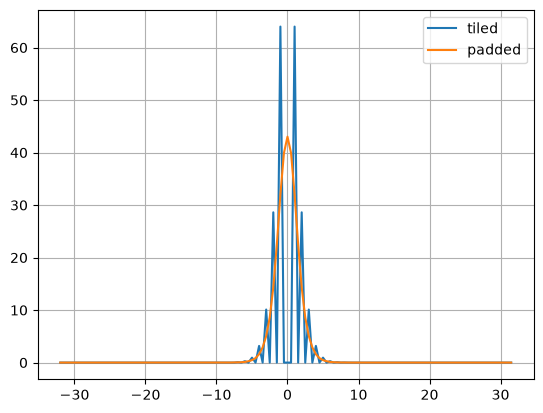

In [10]:
i = 0
order = np.argsort(c1.k)
plt.plot(c1.k[order], np.abs(nf.fft(tiled_sol[i]))[order], label = "tiled")
plt.plot(c1.k[order], np.abs(nf.fft(padded_sol[i]))[order], label = "padded")
plt.grid()
plt.legend()
plt.show()


In [ ]:
Ft = np.fft.rfft(tiled); Fp = np.fft.rfft(padded)
print(np.allclose(np.abs(Fp[2::2]), np.abs(Ft[2::2])/2))   # True (k=0 excluded)
print(np.abs(Ft[1::2]).max(), np.abs(Fp[1::2]).max())      # the odd k's in the padded one, leads to radiation

True
0.0 39.919243058314734
